In [19]:
import os
import sys

print(f'Working directory: {os.getcwd()}')
sys.path.insert(0, os.getcwd())

Working directory: c:\26'interspeech\Monaural_SELD


In [20]:
import torch
import yaml
from torch.utils.data import DataLoader

from models.my_model15 import ResnetConformer_seddoa_nopool_2023
from my_data_loader import LmdbDataset
from utils.sed_doa import process_raw_mic_input
from utils.cls_tools.visualize import _compute_stft_for_frontend, _get_prior_logs

In [21]:
with open('config/my_experiment15.yaml', 'r') as f:
    args = yaml.safe_load(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

model = ResnetConformer_seddoa_nopool_2023(
    in_channel=args['model']['in_channel'],
    in_dim=args['model']['in_dim'],
    out_dim=args['model']['out_dim'],
    norm_path=args['data']['norm_file']
)

ckpt_path = './output/my_experiment15/checkpoints/checkpoint_epoch367_step100000.pth'
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model = model.to(device)
model.eval()
print(f'Loaded: {ckpt_path}')

Using device: cuda
Loaded: ./output/my_experiment15/checkpoints/checkpoint_epoch367_step100000.pth


In [22]:
test_dataset = LmdbDataset(
    args['data']['test_lmdb_dir'],
    [4],
    normalized_features_wts_file=None,
    ignore=args['data']['test_ignore'],
    segment_len=args['data']['test_segment_len'],
    data_process_fn=process_raw_mic_input,
    is_train=False
)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=args['data']['batch_size'],
    shuffle=False,
    num_workers=0,
    collate_fn=test_dataset.collater
)

data = next(iter(test_dataloader))
input_batch = data['input'].to(device)
print(f'Input shape: {input_batch.shape}')

Input shape: torch.Size([32, 4, 500, 480])


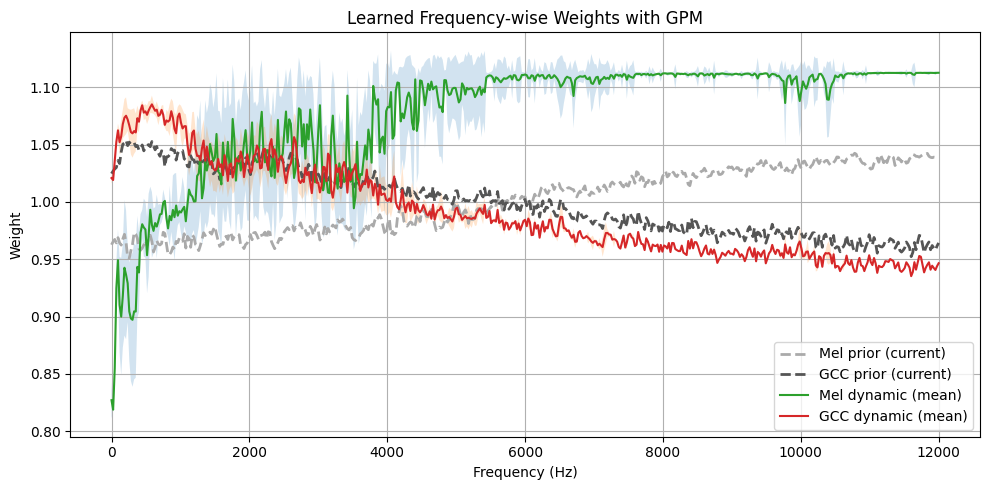

In [23]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

frontend = model.frontend
frontend.eval()

with torch.no_grad():
    stft, mag = _compute_stft_for_frontend(frontend, input_batch)
    mel_w, gcc_w = frontend.get_weights(stft, mag)
    mel_w = mel_w.detach().cpu().numpy()
    gcc_w = gcc_w.detach().cpu().numpy()

    shared_prior_log, mel_prior_log, gcc_prior_log = _get_prior_logs(frontend, mode='current')
    s_scale = frontend.shared_scale.item() if isinstance(frontend.shared_scale, torch.Tensor) else frontend.shared_scale
    r_scale = frontend.residual_scale.item() if isinstance(frontend.residual_scale, torch.Tensor) else frontend.residual_scale
    mel_prior_weight = np.exp(s_scale * shared_prior_log + r_scale * mel_prior_log)
    gcc_prior_weight = np.exp(s_scale * shared_prior_log + r_scale * gcc_prior_log)

freqs = np.linspace(0, 24000 / 2, frontend.n_freqs)

mel_mean = mel_w.mean(axis=0)
gcc_mean = gcc_w.mean(axis=0)
mel_std  = mel_w.std(axis=0)
gcc_std  = gcc_w.std(axis=0)

plt.figure(figsize=(10, 5))
plt.plot(freqs, mel_prior_weight, '--', label='Mel prior (current)', linewidth=2, color='#aaaaaa')
plt.plot(freqs, gcc_prior_weight, '--', label='GCC prior (current)', linewidth=2, color='#555555')
plt.plot(freqs, mel_mean, label='Mel dynamic (mean)', color='tab:green')
plt.plot(freqs, gcc_mean, label='GCC dynamic (mean)', color='tab:red')
plt.fill_between(freqs, mel_mean - mel_std, mel_mean + mel_std, alpha=0.2)
plt.fill_between(freqs, gcc_mean - gcc_std, gcc_mean + gcc_std, alpha=0.2)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Weight')
plt.title('Learned Frequency-wise Weights with GPM')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
from models.my_model17 import ResnetConformer_seddoa_nopool_2023 as ResnetConformer17

with open('config/my_experiment17.yaml', 'r') as f:
    args17 = yaml.safe_load(f)

model17 = ResnetConformer17(
    in_channel=args17['model']['in_channel'],
    in_dim=args17['model']['in_dim'],
    out_dim=args17['model']['out_dim'],
    norm_path=args17['data']['norm_file']
)

ckpt_path17 = './output/my_experiment17/checkpoints/checkpoint_epoch367_step100000.pth'
model17.load_state_dict(torch.load(ckpt_path17, map_location=device))
model17 = model17.to(device)
model17.eval()
print(f'Loaded: {ckpt_path17}')

Loaded: ./output/my_experiment17/checkpoints/checkpoint_epoch367_step100000.pth


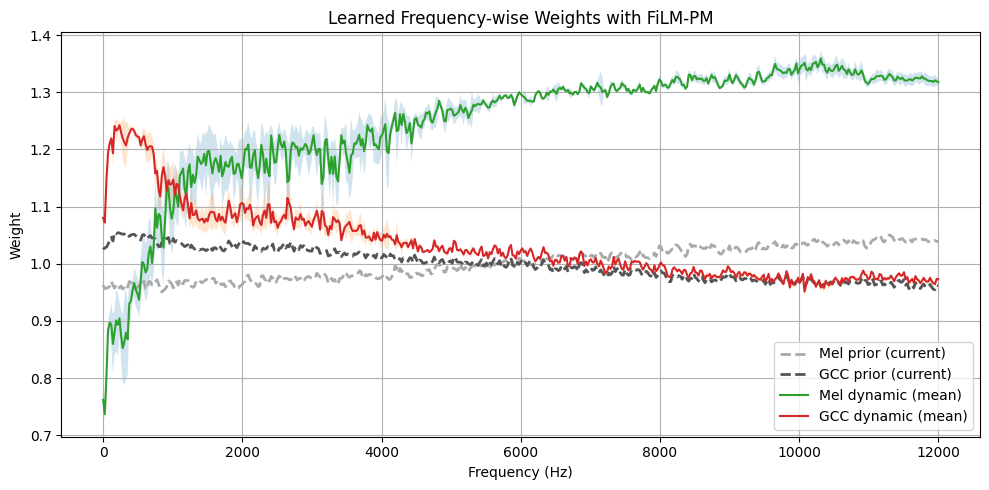

In [25]:
frontend17 = model17.frontend
frontend17.eval()

with torch.no_grad():
    stft, mag = _compute_stft_for_frontend(frontend17, input_batch)
    mel_w, gcc_w = frontend17.get_weights(stft, mag)
    mel_w = mel_w.detach().cpu().numpy()
    gcc_w = gcc_w.detach().cpu().numpy()

    shared_prior_log, mel_prior_log, gcc_prior_log = _get_prior_logs(frontend17, mode='current')
    s_scale = frontend17.shared_scale.item() if isinstance(frontend17.shared_scale, torch.Tensor) else frontend17.shared_scale
    r_scale = frontend17.residual_scale.item() if isinstance(frontend17.residual_scale, torch.Tensor) else frontend17.residual_scale
    mel_prior_weight = np.exp(s_scale * shared_prior_log + r_scale * mel_prior_log)
    gcc_prior_weight = np.exp(s_scale * shared_prior_log + r_scale * gcc_prior_log)

freqs = np.linspace(0, 24000 / 2, frontend17.n_freqs)

mel_mean = mel_w.mean(axis=0)
gcc_mean = gcc_w.mean(axis=0)
mel_std  = mel_w.std(axis=0)
gcc_std  = gcc_w.std(axis=0)

plt.figure(figsize=(10, 5))
plt.plot(freqs, mel_prior_weight, '--', label='Mel prior (current)', linewidth=2, color='#aaaaaa')
plt.plot(freqs, gcc_prior_weight, '--', label='GCC prior (current)', linewidth=2, color='#555555')
plt.plot(freqs, mel_mean, label='Mel dynamic (mean)', color='tab:green')
plt.plot(freqs, gcc_mean, label='GCC dynamic (mean)', color='tab:red')
plt.fill_between(freqs, mel_mean - mel_std, mel_mean + mel_std, alpha=0.2)
plt.fill_between(freqs, gcc_mean - gcc_std, gcc_mean + gcc_std, alpha=0.2)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Weight')
plt.title('Learned Frequency-wise Weights with FiLM-PM')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()